Fase 1: Preparação e Serialização do Modelo (Pipeline Offline)
Treinar (ou refinar) o modelo preditivo escolhido, garantindo a divisão entre dados de treino, validação e teste e os devidos tratamentos de pré-processamento (imputação de nulos, codificação categórica e escalonamento).
Serialização do Artefato: Salvar o pipeline ou modelo treinado em um arquivo binário dedicado (ex.: .joblib ou .pkl) dentro de uma pasta apropriada do projeto (ex.: models/) ou usar um banco de dados sqlite, como explorado em aula ou ainda uma ferramenta mais apropriada e robusta como o MLflow.
Relatório de Métricas: Apresentar em documentação ou script auxiliar as métricas alcançadas pelo modelo selecionado (Acurácia, F1-Score, ROC-AUC, MSE/R² dependendo do tipo de problema).


Importando bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

Carrregando a boblioteca Cleveland


In [2]:
heart = fetch_ucirepo(id=45)

X = heart.data.features
y = heart.data.targets

# CardioPredict Clínico — Análise Exploratória

## Objetivo

Este notebook apresenta a análise exploratória da base Heart Disease — Cleveland, disponibilizada pelo UCI Machine Learning Repository.

O objetivo é investigar a estrutura, a qualidade e a distribuição dos dados, preparando-os para o desenvolvimento de um modelo de classificação binária da presença de doença cardíaca registrada na base.

A análise faz parte da **Fase 1 — Preparação e Serialização do Modelo (Pipeline Offline)** do projeto SENAI.

> **Limitação:** o modelo não será desenvolvido para prever infarto futuro nem substituir avaliação médica.

Conhecendo os dados:

In [3]:
print("Dimensões das variáveis:", X.shape)
print("Dimensões do alvo:", y.shape)

display(X.head())

Dimensões das variáveis: (303, 13)
Dimensões do alvo: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [4]:
print("Tipos das variáveis:")
print(X.dtypes)

print("\nValores ausentes por variável:")
print(X.isnull().sum())

print("\nValores ausentes no alvo:")
print(y.isnull().sum())

Tipos das variáveis:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
dtype: object

Valores ausentes por variável:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
dtype: int64

Valores ausentes no alvo:
num    0
dtype: int64


## 1. Análise da qualidade dos dados

A base Cleveland contém 303 registros, 13 variáveis preditoras e uma variável-alvo denominada `num`.

A investigação de valores ausentes identificou:

- `ca`: 4 valores ausentes.
- `thal`: 2 valores ausentes.
- Demais variáveis: nenhum valor ausente.
- Variável-alvo: nenhum valor ausente.

Os valores ausentes serão tratados posteriormente por técnicas de imputação dentro do pipeline de treinamento, evitando vazamento de informações entre os conjuntos de dados.

Nenhum registro será excluído automaticamente nesta etapa.

In [5]:
print("Distribuição da variável-alvo:")
print(y.value_counts().sort_index())


Distribuição da variável-alvo:
num
0      164
1       55
2       36
3       35
4       13
Name: count, dtype: int64


In [6]:
print("Distribuição original:")
print(y["num"].value_counts().sort_index())

Distribuição original:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


O primeiro modelo será de classificação binária: distinguir os registros classificados com ausência ou presença de doença cardíaca na base Cleveland.

In [7]:
y_binario = (y["num"] > 0).astype(int)

print("Distribuição binária:")
print(y_binario.value_counts().sort_index())


Distribuição binária:
num
0    164
1    139
Name: count, dtype: int64


Nossa variável-alvo binária apresenta:
- 164 pacientes (54,1%) classificados sem doença cardíaca.
- 139 pacientes (45,9%) classificados com doença cardíaca.

## 2. Transformação da variável-alvo

A variável original `num` apresenta cinco categorias:

| Valor | Número de registros |
|---|---:|
| 0 | 164 |
| 1 | 55 |
| 2 | 36 |
| 3 | 35 |
| 4 | 13 |

Para o problema de classificação binária, adotou-se:

- **Classe 0:** ausência de doença cardíaca na classificação da base.
- **Classe 1:** presença de doença cardíaca na classificação da base (valores originais de 1 a 4).

Após a transformação, foram obtidos:

- Classe 0: 164 registros (54,1%).
- Classe 1: 139 registros (45,9%).

A distribuição não apresenta desequilíbrio extremo entre as classes.

Gráfico de distribuição da doenca cardíaca:

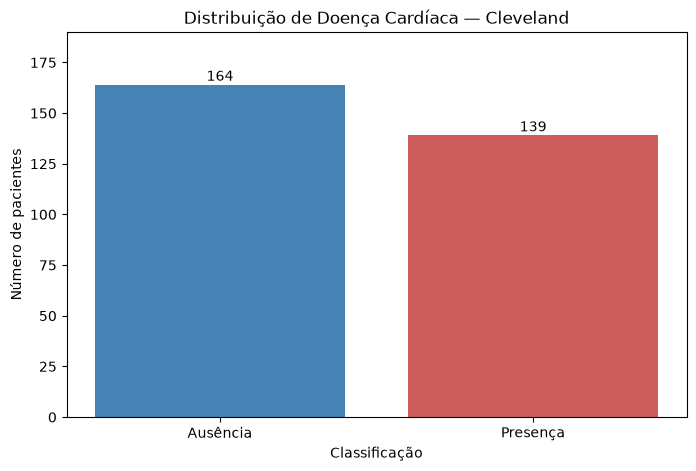

In [8]:
import matplotlib.pyplot as plt

contagem = y_binario.value_counts().sort_index()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    ["Ausência", "Presença"],
    contagem.values,
    color=["steelblue", "indianred"]
)

plt.title("Distribuição de Doença Cardíaca — Cleveland")
plt.xlabel("Classificação")
plt.ylabel("Número de pacientes")

for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 2,
        str(int(altura)),
        ha="center"
    )

plt.ylim(0, 190)
plt.show()

Classificação das variáveis clínicas

In [9]:
variaveis_numericas = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

variaveis_categoricas = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Variáveis numéricas:", len(variaveis_numericas))
print("Variáveis categóricas:", len(variaveis_categoricas))

print("\nTotal de variáveis:",
      len(variaveis_numericas) + len(variaveis_categoricas))

print("\nEstatísticas das variáveis numéricas:")
display(X[variaveis_numericas].describe())

Variáveis numéricas: 5
Variáveis categóricas: 8

Total de variáveis: 13

Estatísticas das variáveis numéricas:


,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,131.689769,246.693069,149.607261,1.039604
std,9.038662,17.599748,51.776918,22.875003,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.500000,0.000000
50%,56.000000,130.000000,241.000000,153.000000,0.800000
75%,61.000000,140.000000,275.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


## 3. Caracterização das variáveis preditoras

As 13 variáveis foram organizadas em dois grupos para orientar o pré-processamento.

### Variáveis numéricas (5)

- `age`: idade.
- `trestbps`: pressão arterial em repouso.
- `chol`: colesterol sérico.
- `thalach`: frequência cardíaca máxima alcançada.
- `oldpeak`: depressão do segmento ST.

### Variáveis categóricas (8)

- `sex`: sexo codificado.
- `cp`: tipo de dor torácica.
- `fbs`: glicemia de jejum acima de 120 mg/dL.
- `restecg`: resultado do ECG em repouso.
- `exang`: angina induzida por exercício.
- `slope`: inclinação do segmento ST.
- `ca`: número de vasos principais visualizados, tratado inicialmente como categoria.
- `thal`: resultado codificado de exame.

### Estatísticas descritivas

As médias observadas foram:

- Idade: 54,44 anos.
- Pressão arterial em repouso: 131,69 mmHg.
- Colesterol sérico: 246,69 mg/dL.
- Frequência cardíaca máxima: 149,61 bpm.
- Oldpeak: 1,04.

Esses valores descrevem a amostra e não representam estimativas individuais de risco cardiovascular.

In [10]:
from sklearn.model_selection import train_test_split

X_treino, X_temporario, y_treino, y_temporario = train_test_split(
    X,
    y_binario,
    test_size=0.40,
    random_state=42,
    stratify=y_binario
)

X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temporario,
    y_temporario,
    test_size=0.50,
    random_state=42,
    stratify=y_temporario
)

print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Treino: (181, 13)
Validação: (61, 13)
Teste: (61, 13)


## 4. Divisão dos dados em treino, validação e teste

Foi definida uma estratégia de separação dos dados em três conjuntos independentes.

| Conjunto | Proporção | Finalidade |
|---|---:|---|
| Treino | 60% | Ajustar o pré-processamento e treinar o modelo |
| Validação | 20% | Comparar modelos e selecionar hiperparâmetros |
| Teste | 20% | Avaliar o desempenho final do modelo selecionado |

A divisão utiliza `train_test_split`, com:

- `random_state=42`, garantindo reprodutibilidade.
- `stratify`, preservando aproximadamente a distribuição das classes.

O conjunto de teste será mantido separado durante o treinamento e a seleção do modelo.

### Prevenção de vazamento de dados

A imputação, a codificação categórica e o escalonamento serão incorporados a um pipeline do scikit-learn.

Os parâmetros de pré-processamento serão ajustados exclusivamente com os dados de treino, evitando vazamento de informações dos conjuntos de validação e teste.

Essa estratégia permite uma avaliação mais confiável do desempenho do classificador.

In [11]:
from sklearn.model_selection import train_test_split

X_treino, X_temporario, y_treino, y_temporario = train_test_split(
    X,
    y_binario,
    test_size=0.40,
    random_state=42,
    stratify=y_binario
)

X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temporario,
    y_temporario,
    test_size=0.50,
    random_state=42,
    stratify=y_temporario
)

print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Treino: (181, 13)
Validação: (61, 13)
Teste: (61, 13)


Conferir a distribuição das classes:

In [12]:
for nome, alvo in [
    ("Treino", y_treino),
    ("Validação", y_validacao),
    ("Teste", y_teste)
]:
    print(f"\n{nome}")
    print(alvo.value_counts().sort_index())
    print("Percentual positivo:",
          round(alvo.mean() * 100, 2), "%")


Treino
num
0    98
1    83
Name: count, dtype: int64
Percentual positivo: 45.86 %

Validação
num
0    33
1    28
Name: count, dtype: int64
Percentual positivo: 45.9 %

Teste
num
0    33
1    28
Name: count, dtype: int64
Percentual positivo: 45.9 %


## 4. Separação dos dados em treino, validação e teste

A base Cleveland foi dividida em três conjuntos independentes,
utilizando uma estratégia estratificada:

- **Treino (60%):** utilizado para ajustar o pré-processamento
  e treinar o classificador.
- **Validação (20%):** utilizado para comparar modelos e
  selecionar hiperparâmetros.
- **Teste (20%):** reservado para a avaliação final.

Foi utilizado `random_state=42` para permitir a reprodução
dos resultados.

A estratificação preserva aproximadamente a proporção
das classes em cada conjunto.

Nenhuma transformação que aprenda parâmetros dos dados,
como imputação ou escalonamento, foi ajustada antes
dessa separação, prevenindo vazamento de dados.

## 5. Construção do pipeline de pré-processamento

O pré-processamento foi organizado conforme o tipo de variável.

### Variáveis numéricas
- Imputação pela mediana.
- Padronização com StandardScaler.

### Variáveis categóricas
- Imputação pela moda (categoria mais frequente).
- Codificação One-Hot.

As transformações serão organizadas com ColumnTransformer.

Para evitar vazamento de dados, os parâmetros de
pré-processamento serão aprendidos exclusivamente
a partir do conjunto de treinamento.

Os conjuntos de validação e teste não serão utilizados
no ajuste dessas transformações.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

pipeline_numerico = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median")),
    ("escalonamento", StandardScaler())
])

pipeline_categorico = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, variaveis_numericas),
        ("categoricas", pipeline_categorico, variaveis_categoricas)
    ]
)

print("Pré-processador construído com sucesso!")
print(preprocessador)

Pré-processador construído com sucesso!
ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputacao',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalonamento',
                                                  StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('categoricas',
                                 Pipeline(steps=[('imputacao',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('codificacao',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])


## 6. Construção do modelo inicial de classificação

Foi selecionada a Regressão Logística como primeiro
algoritmo de classificação binária.

O modelo será integrado ao pré-processador por meio
de um Pipeline do scikit-learn.

Essa integração garante que as etapas de imputação,
codificação categórica e escalonamento sejam executadas
antes da classificação.

O treinamento utilizará exclusivamente o conjunto
de treino, preservando os conjuntos de validação
e teste para avaliação posterior.

A Regressão Logística será utilizada como modelo
de referência para comparação com outros algoritmos.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone

modelo_logistico = Pipeline(steps=[
    ("preprocessamento", clone(preprocessador)),
    ("classificador", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Pipeline de classificação construído!")
print(modelo_logistico)

Pipeline de classificação construído!
Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escalonamento',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('categoricas',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificacao',
                   

## 7. Treinamento do modelo de Regressão Logística

O modelo inicial foi desenvolvido utilizando Regressão Logística,
integrada a um pipeline de pré-processamento do scikit-learn.

O treinamento utiliza exclusivamente os 181 registros do
conjunto de treino.

Durante o treinamento, o pipeline realiza automaticamente:

1. Imputação dos valores ausentes.
2. Escalonamento das variáveis numéricas.
3. Codificação das variáveis categóricas.
4. Ajuste do classificador de Regressão Logística.

Os conjuntos de validação e teste permanecem separados,
evitando vazamento de informações durante o treinamento.

In [15]:
modelo_logistico.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")
print("Registros utilizados:", len(X_treino))
print("Modelo:", modelo_logistico.named_steps["classificador"])

Modelo treinado com sucesso!
Registros utilizados: 181
Modelo: LogisticRegression(max_iter=1000, random_state=42)


In [16]:
modelo_logistico.fit(X_treino, y_treino)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rem

## 8. Avaliação do modelo no conjunto de validação

O desempenho inicial do classificador de Regressão Logística
será avaliado utilizando os 61 registros do conjunto de validação.

Serão calculadas as seguintes métricas:

- **Acurácia:** proporção de classificações corretas.
- **Precisão:** proporção de classificações positivas corretas.
- **Sensibilidade (Recall):** capacidade de identificar registros positivos.
- **Especificidade:** capacidade de identificar registros negativos.
- **F1-Score:** média harmônica entre precisão e sensibilidade.
- **ROC-AUC:** capacidade de discriminação entre as classes.

O conjunto de teste permanecerá reservado para a avaliação
final, após a seleção do modelo.

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Previsões no conjunto de validação
y_previsto = modelo_logistico.predict(X_validacao)

# Probabilidades da classe positiva
y_probabilidade = modelo_logistico.predict_proba(
    X_validacao
)[:, 1]

# Métricas
acuracia = accuracy_score(y_validacao, y_previsto)
precisao = precision_score(y_validacao, y_previsto)
sensibilidade = recall_score(y_validacao, y_previsto)
f1 = f1_score(y_validacao, y_previsto)
auc = roc_auc_score(y_validacao, y_probabilidade)

# Matriz de confusão
tn, fp, fn, tp = confusion_matrix(
    y_validacao, y_previsto, labels=[0, 1]
).ravel()

especificidade = tn / (tn + fp)

print("RESULTADOS — REGRESSÃO LOGÍSTICA")
print("-" * 40)

print(f"Acurácia:       {acuracia:.4f}")
print(f"Precisão:       {precisao:.4f}")
print(f"Sensibilidade:  {sensibilidade:.4f}")
print(f"Especificidade: {especificidade:.4f}")
print(f"F1-Score:       {f1:.4f}")
print(f"ROC-AUC:        {auc:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_validacao, y_previsto))

RESULTADOS — REGRESSÃO LOGÍSTICA
----------------------------------------
Acurácia:       0.8525
Precisão:       0.8065
Sensibilidade:  0.8929
Especificidade: 0.8182
F1-Score:       0.8475
ROC-AUC:        0.9372

Matriz de confusão:
[[27  6]
 [ 3 25]]


Matriz de confusão — Regressão Logística

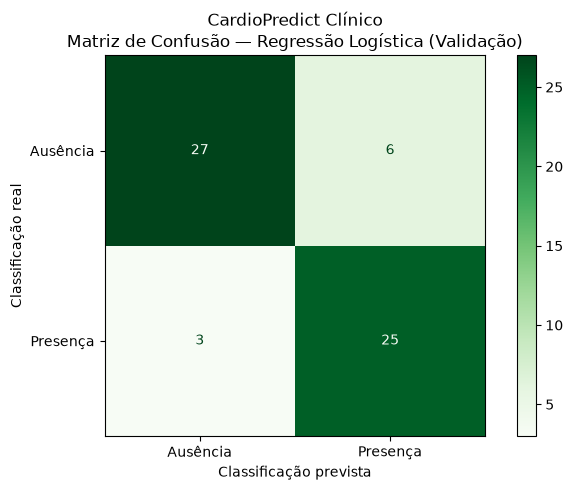

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_estimator(
    modelo_logistico,
    X_validacao,
    y_validacao,
    display_labels=["Ausência", "Presença"],
    cmap="Greens",
    values_format="d",
    ax=ax
)

ax.set_title(
    "CardioPredict Clínico\n"
    "Matriz de Confusão — Regressão Logística (Validação)"
)

ax.set_xlabel("Classificação prevista")
ax.set_ylabel("Classificação real")

plt.tight_layout()
plt.show()

### 8.1 Resultados da Regressão Logística

O modelo foi avaliado em 61 registros de validação.

| Métrica | Resultado |
|---|---:|
| Acurácia | 85,25% |
| Precisão | 80,65% |
| Sensibilidade | 89,29% |
| Especificidade | 81,82% |
| F1-Score | 84,75% |
| ROC-AUC | 93,72% |

A matriz de confusão apresentou:

- 27 verdadeiros negativos.
- 6 falsos positivos.
- 3 falsos negativos.
- 25 verdadeiros positivos.

O modelo apresentou capacidade discriminatória promissora
na amostra de validação.

Entretanto, os resultados não representam validação clínica
externa e não autorizam seu uso para decisões assistenciais.

O conjunto de teste permanece reservado para a avaliação final.

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

modelo_floresta = Pipeline(steps=[
    ("preprocessamento", clone(preprocessador)),
    ("classificador", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

modelo_floresta.fit(X_treino, y_treino)

print("Random Forest treinado com sucesso!")
print("Registros utilizados:", len(X_treino))

Random Forest treinado com sucesso!
Registros utilizados: 181


Avaliação da Random Forest:

In [19]:
y_previsto_floresta = modelo_floresta.predict(X_validacao)

y_probabilidade_floresta = modelo_floresta.predict_proba(
    X_validacao
)[:, 1]

matriz_floresta = confusion_matrix(
    y_validacao,
    y_previsto_floresta,
    labels=[0, 1]
)

vn, fp, fn, vp = matriz_floresta.ravel()

print("RESULTADOS — RANDOM FOREST")
print("-" * 40)

print(f"Acurácia:       {accuracy_score(y_validacao, y_previsto_floresta):.4f}")
print(f"Precisão:       {precision_score(y_validacao, y_previsto_floresta):.4f}")
print(f"Sensibilidade:  {recall_score(y_validacao, y_previsto_floresta):.4f}")
print(f"Especificidade: {vn / (vn + fp):.4f}")
print(f"F1-Score:       {f1_score(y_validacao, y_previsto_floresta):.4f}")
print(f"ROC-AUC:        {roc_auc_score(y_validacao, y_probabilidade_floresta):.4f}")

print("\nMatriz de confusão:")
print(matriz_floresta)

RESULTADOS — RANDOM FOREST
----------------------------------------
Acurácia:       0.8689
Precisão:       0.8125
Sensibilidade:  0.9286
Especificidade: 0.8182
F1-Score:       0.8667
ROC-AUC:        0.9389

Matriz de confusão:
[[27  6]
 [ 2 26]]


Matriz de confusão — Random Forest (validação):

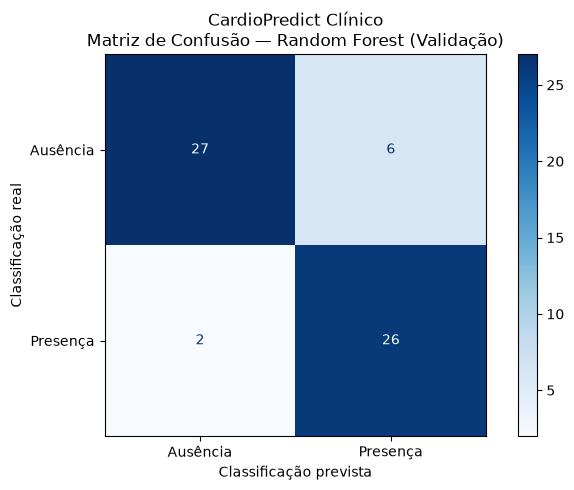

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Matriz de confusão da Random Forest na validação
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_estimator(
    modelo_floresta,
    X_validacao,
    y_validacao,
    display_labels=["Ausência", "Presença"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "CardioPredict Clínico\n"
    "Matriz de Confusão — Random Forest (Validação)"
)

ax.set_xlabel("Classificação prevista")
ax.set_ylabel("Classificação real")

plt.tight_layout()
plt.show()

## 10. Comparação e seleção do classificador

Foram comparados dois algoritmos de classificação binária:
Regressão Logística e Random Forest.

Ambos utilizaram o mesmo conjunto de treinamento, o mesmo
pré-processamento e o mesmo conjunto de validação.

| Métrica | Regressão Logística | Random Forest |
|---|---:|---:|
| Acurácia | 0.8525 | 0.8689 |
| Precisão | 0.8065 | 0.8125 |
| Sensibilidade | 0.8929 | 0.9286 |
| Especificidade | 0.8182 | 0.8182 |
| F1-Score | 0.8475 | 0.8667 |
| ROC-AUC | 0.9372 | 0.9389 |

### Seleção preliminar

A Random Forest apresentou desempenho ligeiramente superior
na validação, especialmente em sensibilidade e F1-Score.

A matriz de confusão apresentou:
- 27 verdadeiros negativos.
- 6 falsos positivos.
- 2 falsos negativos.
- 26 verdadeiros positivos.

A Random Forest foi selecionada como candidata ao modelo
final, considerando o desempenho observado na validação.

Essa seleção é preliminar e está sujeita às limitações
do pequeno conjunto de dados.

O conjunto de teste ainda não foi utilizado.

## 11. Avaliação final no conjunto de teste

Após a comparação no conjunto de validação, a Random Forest
foi selecionada como modelo candidato final.

O modelo será avaliado uma única vez nos 61 registros
reservados para teste.

Serão calculadas acurácia, precisão, sensibilidade,
especificidade, F1-Score e ROC-AUC.

Os resultados serão documentados como estimativas de
desempenho em dados não utilizados no treinamento
ou na seleção do modelo.

In [22]:
# Avaliação final no conjunto de teste

y_teste_previsto = modelo_floresta.predict(X_teste)

y_teste_probabilidade = modelo_floresta.predict_proba(
    X_teste
)[:, 1]

matriz_teste = confusion_matrix(
    y_teste,
    y_teste_previsto,
    labels=[0, 1]
)

vn, fp, fn, vp = matriz_teste.ravel()

print("CARDIOPREDICT — TESTE FINAL")
print("-" * 40)

print(f"Acurácia:       {accuracy_score(y_teste, y_teste_previsto):.4f}")
print(f"Precisão:       {precision_score(y_teste, y_teste_previsto):.4f}")
print(f"Sensibilidade:  {recall_score(y_teste, y_teste_previsto):.4f}")
print(f"Especificidade: {vn / (vn + fp):.4f}")
print(f"F1-Score:       {f1_score(y_teste, y_teste_previsto):.4f}")
print(f"ROC-AUC:        {roc_auc_score(y_teste, y_teste_probabilidade):.4f}")

print("\nMatriz de confusão:")
print(matriz_teste)

CARDIOPREDICT — TESTE FINAL
----------------------------------------
Acurácia:       0.8197
Precisão:       0.7931
Sensibilidade:  0.8214
Especificidade: 0.8182
F1-Score:       0.8070
ROC-AUC:        0.9248

Matriz de confusão:
[[27  6]
 [ 5 23]]


## 11.1 Resultados finais no conjunto de teste

O modelo Random Forest, selecionado previamente com base
no desempenho de validação, foi avaliado nos 61 registros
reservados para teste.

| Métrica | Resultado |
|---|---:|
| Acurácia | 81,97% |
| Precisão | 79,31% |
| Sensibilidade | 82,14% |
| Especificidade | 81,82% |
| F1-Score | 80,70% |
| ROC-AUC | 92,48% |

### Matriz de confusão

- Verdadeiros negativos: 27
- Falsos positivos: 6
- Falsos negativos: 5
- Verdadeiros positivos: 23

O classificador apresentou desempenho discriminatório
promissor na base histórica Cleveland.

Entretanto, a redução da sensibilidade em relação à
validação evidencia limitações de generalização.

Os resultados não constituem validação clínica externa
e não autorizam o uso do sistema como ferramenta de
diagnóstico ou decisão médica.

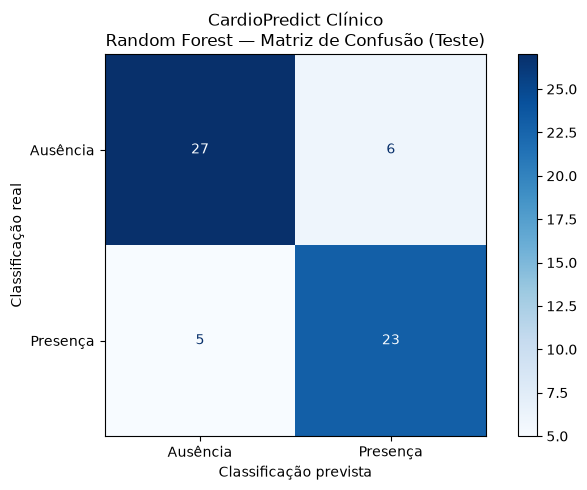

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    y_teste_previsto,
    labels=[0, 1],
    display_labels=["Ausência", "Presença"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title(
    "CardioPredict Clínico\n"
    "Random Forest — Matriz de Confusão (Teste)"
)

ax.set_xlabel("Classificação prevista")
ax.set_ylabel("Classificação real")

plt.tight_layout()
plt.show()

## 12. Serialização do modelo treinado

Após a comparação dos classificadores, a Random Forest
foi selecionada com base no desempenho de validação.

O pipeline completo será serializado utilizando a
biblioteca joblib.

O arquivo contém:

- Imputação de valores ausentes.
- Escalonamento das variáveis numéricas.
- Codificação das variáveis categóricas.
- Classificador Random Forest treinado.

A serialização permite reutilizar o mesmo pipeline
na futura API FastAPI, sem realizar novo treinamento
a cada requisição.

O modelo foi treinado exclusivamente nos dados de treino,
e seu desempenho final foi avaliado no conjunto de teste.

In [24]:
from pathlib import Path
import joblib

# Identificar a pasta raiz do projeto
diretorio_atual = Path.cwd()

if diretorio_atual.name == "notebooks":
    raiz_projeto = diretorio_atual.parent
else:
    raiz_projeto = diretorio_atual

# Criar a pasta models, caso não exista
pasta_modelos = raiz_projeto / "models"
pasta_modelos.mkdir(parents=True, exist_ok=True)

# Caminho do arquivo
caminho_modelo = pasta_modelos / "cardiopredict_pipeline.joblib"

# Salvar o pipeline completo
joblib.dump(modelo_floresta, caminho_modelo)

print("Modelo serializado com sucesso!")
print("Arquivo:", caminho_modelo)
print("Tamanho:", round(caminho_modelo.stat().st_size / 1024, 2), "KB")

Modelo serializado com sucesso!
Arquivo: e:\CardioPredict-AI\models\cardiopredict_pipeline.joblib
Tamanho: 1212.53 KB


Verificar se o arquivo funciona:

In [25]:
# Carregar o pipeline salvo
modelo_carregado = joblib.load(caminho_modelo)

# Comparar previsões com o modelo original
previsoes_originais = modelo_floresta.predict(X_validacao)
previsoes_carregadas = modelo_carregado.predict(X_validacao)

import numpy as np

iguais = np.array_equal(
    previsoes_originais,
    previsoes_carregadas
)

print("Modelo carregado com sucesso!")
print("Previsões idênticas:", iguais)

Modelo carregado com sucesso!
Previsões idênticas: True


## 13. Relatório de métricas do modelo final

O desempenho do modelo Random Forest foi documentado
a partir da avaliação realizada no conjunto de teste.

O relatório inclui:

- Algoritmo utilizado.
- Quantidade de registros de treino, validação e teste.
- Acurácia, precisão, sensibilidade, especificidade,
  F1-Score e ROC-AUC.
- Matriz de confusão.
- Nome do arquivo do modelo serializado.

O relatório será armazenado em formato JSON, permitindo
sua consulta e utilização na documentação do projeto.

Os resultados representam uma avaliação experimental
na base Cleveland, não uma validação clínica externa.

In [26]:
import json
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Criar pasta para relatórios
pasta_relatorios = raiz_projeto / "reports"
pasta_relatorios.mkdir(parents=True, exist_ok=True)

# Calcular métricas do teste final
matriz_final = confusion_matrix(
    y_teste,
    y_teste_previsto,
    labels=[0, 1]
)

vn, fp, fn, vp = matriz_final.ravel()

relatorio = {
    "projeto": "CardioPredict Clínico",
    "base_dados": "UCI Heart Disease - Cleveland",
    "modelo": "RandomForestClassifier",
    "arquivo_modelo": "models/cardiopredict_pipeline.joblib",
    "registros": {
        "treino": len(X_treino),
        "validacao": len(X_validacao),
        "teste": len(X_teste)
    },
    "metricas_teste": {
        "acuracia": round(accuracy_score(y_teste, y_teste_previsto), 4),
        "precisao": round(precision_score(y_teste, y_teste_previsto), 4),
        "sensibilidade": round(recall_score(y_teste, y_teste_previsto), 4),
        "especificidade": round(vn / (vn + fp), 4),
        "f1_score": round(f1_score(y_teste, y_teste_previsto), 4),
        "roc_auc": round(roc_auc_score(y_teste, y_teste_probabilidade), 4)
    },
    "matriz_confusao": matriz_final.tolist(),
    "observacao": "Modelo experimental. Não validado para uso clínico."
}

caminho_relatorio = pasta_relatorios / "metricas_modelo.json"

with open(caminho_relatorio, "w", encoding="utf-8") as arquivo:
    json.dump(relatorio, arquivo, indent=4, ensure_ascii=False)

print("Relatório gerado com sucesso!")
print("Arquivo:", caminho_relatorio)

Relatório gerado com sucesso!
Arquivo: e:\CardioPredict-AI\reports\metricas_modelo.json
